# Grad-CAM Visualization — Correct vs. Wrong Predictions

Loads the per-image Grad-CAM maps saved by `c0_predict_medmnist.py` and overlays them on the
original ChestMNIST X-rays, split into correctly and incorrectly classified examples.

In [20]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from medmnist import ChestMNIST

In [21]:
plt.rcParams.update({
    'font.size': 17,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
})

In [22]:
BASE_DIR = "/zhome/d0/a/221493/thesis"
DATA_DIR = os.path.join(BASE_DIR, "data")                  # raw images (CheXpert, custom, ...)
MEDMNIST_DATA_DIR = os.path.join(DATA_DIR, "medmnist")      # medmnist npz-backed dataset

DISEASE = "effusion"
MODEL   = "C0_custom"
SPLIT   = "val"          # "train", "val", or "test" (medmnist); "train"/"val" for C0_custom
N_EXAMPLES = 8             # examples per group to plot

RESULTS_DIR = os.path.join(BASE_DIR, "results", MODEL, DISEASE)

In [23]:
df = pd.read_csv(os.path.join(RESULTS_DIR, f"{SPLIT}_c0_{DISEASE}.csv"))
n_before = len(df)

# Restrict to samples that actually made it into C2 training/testing, i.e. the same
# filtering c1_match_to_new_split.py applies before writing c2_data.csv:
#   1) frontal views only (CheXpert has frontal + lateral views per study)
#   2) inner-joined on `path` with the C1 attribute vector (only matched paths survive)
if df["path"].str.contains("frontal").any():
    df = df[df["path"].str.contains("frontal")]

C1_ATTRIBUTE_FILES = {
    "C0_custom": os.path.join(BASE_DIR, "results", "C1_attributes", "train_c1_attribute_vector_rad.csv"),
    "C0_medmnist": os.path.join(BASE_DIR, "results", "C1_medmnist", DISEASE, f"{SPLIT}_c1_attributes.csv"),
}
c1_matched_paths = set(pd.read_csv(C1_ATTRIBUTE_FILES[MODEL], usecols=["path"])["path"])
df = df[df["path"].isin(c1_matched_paths)].reset_index(drop=True)

print(f"{n_before:,} -> {len(df):,} samples after frontal + C1-match filtering")

df["outcome"] = np.select(
    [
        (df["true"] == 1) & (df["pred"] == 1),
        (df["true"] == 0) & (df["pred"] == 1),
        (df["true"] == 0) & (df["pred"] == 0),
        (df["true"] == 1) & (df["pred"] == 0),
    ],
    ["TP", "FP", "TN", "FN"],
)

print(df["outcome"].value_counts())
df[["path", "prob", "true", "pred", "correct", "margin", "outcome"]].head()

61,442 -> 45,155 samples after frontal + C1-match filtering
outcome
TP    32053
TN     9365
FN     2469
FP     1268
Name: count, dtype: int64


,path,prob,true,pred,correct,margin,outcome
0,CheXpert-v1.0-small/train/patient00005/study1/...,0.041813,0.0,0,1,0.521546,TN
1,CheXpert-v1.0-small/train/patient00006/study1/...,0.215646,0.0,0,1,0.347713,TN
2,CheXpert-v1.0-small/train/patient00008/study1/...,0.989891,1.0,1,1,0.426532,TP
3,CheXpert-v1.0-small/train/patient00008/study2/...,0.803473,1.0,1,1,0.240114,TP
4,CheXpert-v1.0-small/train/patient00010/study1/...,0.022443,0.0,0,1,0.540917,TN


## Helpers: load original image + Grad-CAM overlay

In [24]:
_ds_cache = {}
_MEDMNIST_PATH_RE = re.compile(r"^(train|val|test)/\d+$")


def get_dataset(split):
    if split not in _ds_cache:
        _ds_cache[split] = ChestMNIST(split=split, size=224, download=False,
                                       root=MEDMNIST_DATA_DIR, transform=None)
    return _ds_cache[split]


def load_image(path):
    """Grayscale numpy array for either a medmnist 'split/000123' path
    or a real file path relative to DATA_DIR (e.g. CheXpert 'CheXpert-v1.0-small/...')."""
    if _MEDMNIST_PATH_RE.match(path):
        split, idx = path.split("/")
        img, _ = get_dataset(split)[int(idx)]
    else:
        img = Image.open(os.path.join(DATA_DIR, path)).convert("L")
    return np.array(img)


def load_cam(cam_path, size):
    """size is (H, W) of the target image; cv2.resize wants (W, H).

    Some CSVs (e.g. C0_custom) record cam_path without the trailing .npz that the
    file actually has on disk, so fall back to appending it.

    Cubic interpolation can overshoot past [0, 1] near sharp transitions in the
    coarse 7x7 grid (e.g. edges/corners), so clip before it's ever cast to uint8 —
    otherwise negative/over-1 values wrap around mod 256 into spurious bright colors.
    """
    if not os.path.exists(cam_path) and os.path.exists(cam_path + ".npz"):
        cam_path = cam_path + ".npz"
    cam = np.load(cam_path)["cam"]
    cam = cv2.resize(cam, (size[1], size[0]), interpolation=cv2.INTER_CUBIC)
    return np.clip(cam, 0.0, 1.0)


def overlay_cam(img_gray, cam, alpha=0.4):
    """Blend a jet-colormapped Grad-CAM heatmap onto a grayscale image."""
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    img_rgb = np.stack([img_gray] * 3, axis=-1)
    return (alpha * heatmap + (1 - alpha) * img_rgb).astype(np.uint8)

## Grid plotting helper

In [25]:
def plot_gradcam_grid(rows, title, n_cols=4):
    n = len(rows)
    n_cols = min(n_cols, n) if n else 1
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.6 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (_, row) in zip(axes, rows.iterrows()):
        img = load_image(row["path"])
        cam = load_cam(row["cam_path"], size=img.shape[:2])
        ax.imshow(overlay_cam(img, cam))
        ax.set_title(f"{row['outcome']} | prob={row['prob']:.2f} | true={int(row['true'])}",
                      fontsize=10)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

## Correct predictions

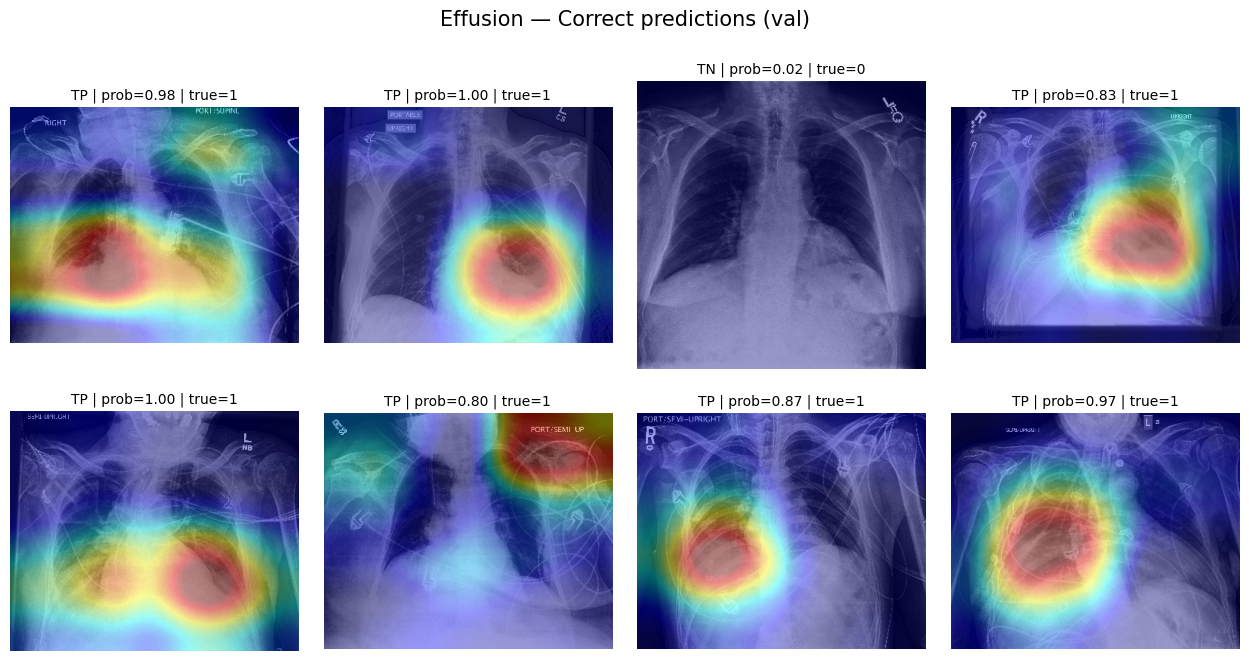

In [26]:
correct_sample = df[df["correct"] == 1].sample(n=N_EXAMPLES, random_state=0)
plot_gradcam_grid(correct_sample, f"{DISEASE.title()} — Correct predictions ({SPLIT})")

## Wrong predictions

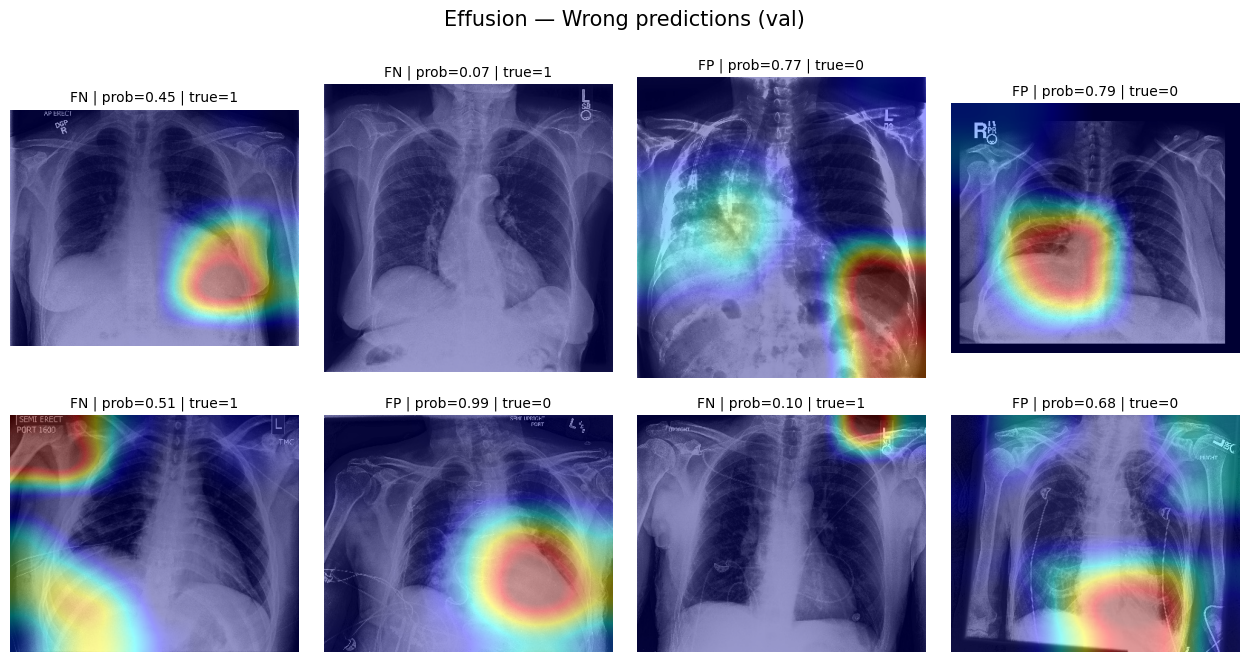

In [27]:
wrong_pool = df[df["correct"] == 0]
wrong_sample = wrong_pool.sample(n=min(N_EXAMPLES, len(wrong_pool)), random_state=0)
plot_gradcam_grid(wrong_sample, f"{DISEASE.title()} — Wrong predictions ({SPLIT})")

## Optional: break wrong predictions down into FP vs FN

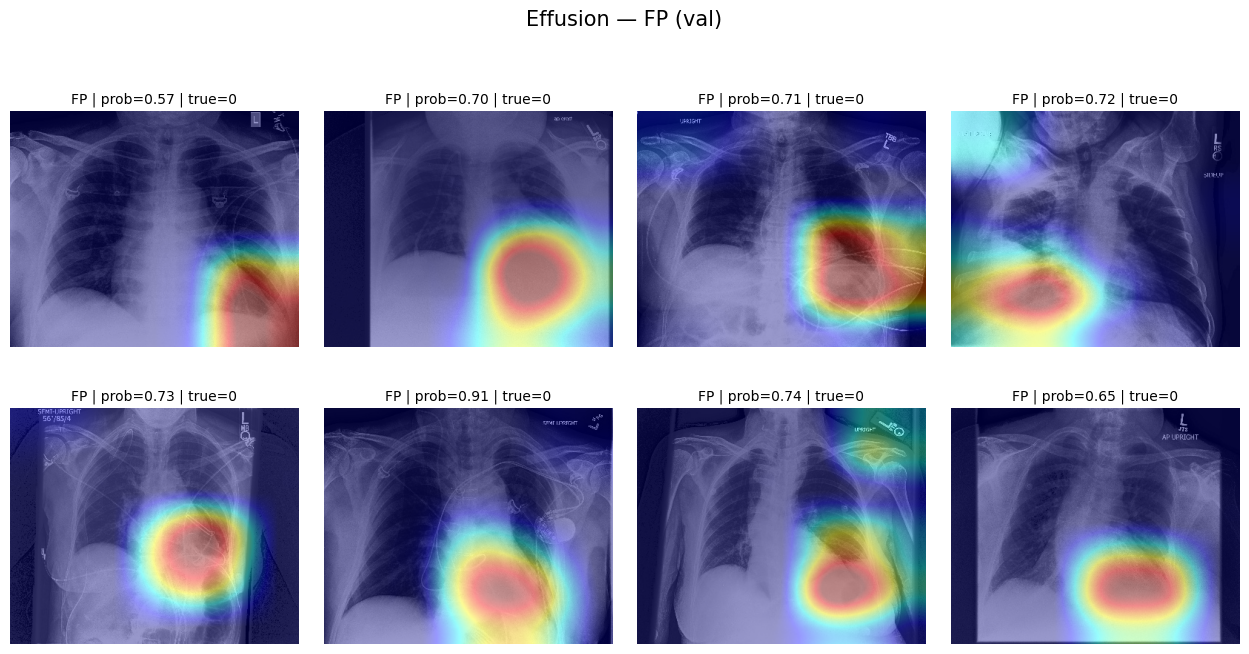

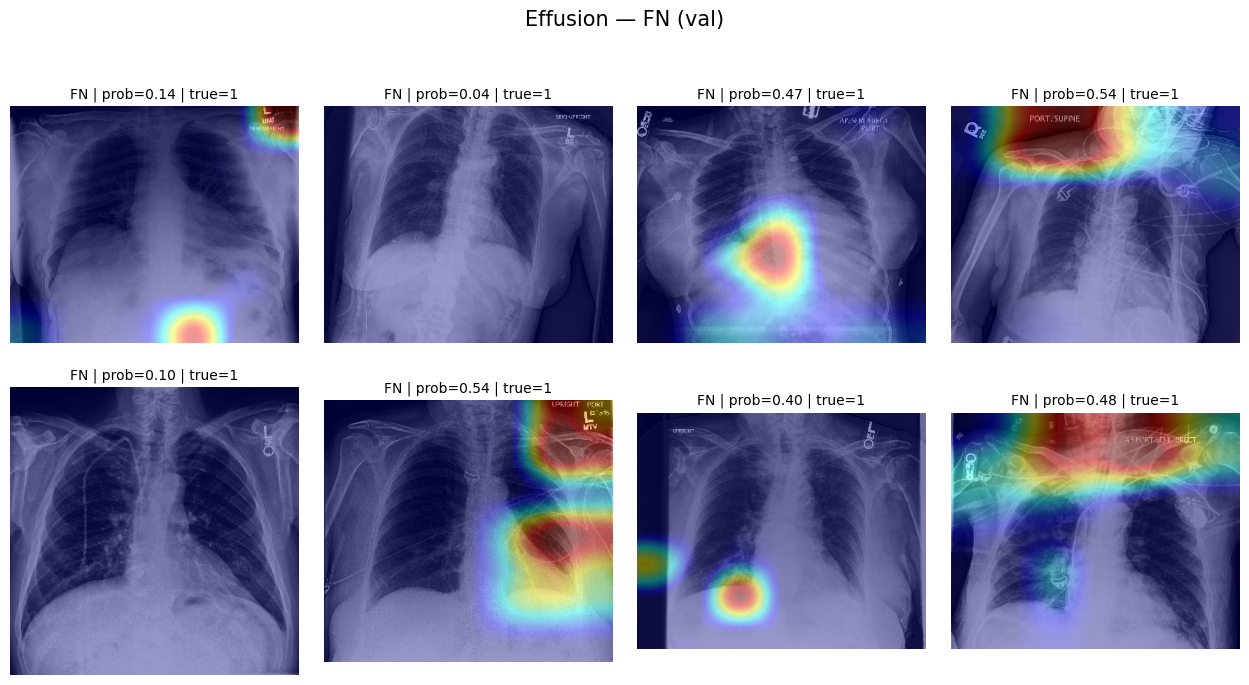

In [28]:
for outcome in ["FP", "FN"]:
    pool = df[df["outcome"] == outcome]
    if pool.empty:
        print(f"No {outcome} examples in this split.")
        continue
    sample = pool.sample(n=min(N_EXAMPLES, len(pool)), random_state=0)
    plot_gradcam_grid(sample, f"{DISEASE.title()} — {outcome} ({SPLIT})")